# 04 · Loss-risk model: can we flag loss-making lines before fulfillment?

**Roadmap step 4.** Business question:

> *Which features known at order time (e.g. product category, region, ship mode, discount
> level) are the strongest predictors of loss-making order lines, and can we flag
> high-risk transactions before fulfillment better than a simple discount rule?*

**Design** (agreed before modelling; code in `src/loss_model.py`):

| Choice | What | Why |
|---|---|---|
| Unit / target | one order line / `is_loss` (profit < 0) | the decision is made per line, before fulfillment |
| Features | discount, category, sub-category, region, state, ship mode, segment, quantity, list unit price, order month | all known when the order is placed |
| Excluded | profit, margin, sales, outlier flags, **every step 3 customer table** | they define the target or summarize future orders (a test enforces this) |
| Split | train 2014-2016, test 2017 (used once) | a random split would let the model learn from the future |
| Tuning | expanding windows: 2014 → 2015, 2014-15 → 2016 | same logic inside the training years |
| Baseline A | flag if discount > 20% | the rule from step 2 |
| Baseline B | A + lines discounted 1-20% whose sub-category lost money in that band ≥ threshold (training years) | is a two-variable rule enough? |
| Models | Logistic Regression, Random Forest | |
| Primary metric | PR-AUC on 2017 | suits a 19% positive rate |
| Business metric | precision, recall and **share of loss dollars caught** at a fixed number of flagged lines | |
| Focus band | lines discounted 1-20% | Baseline A cannot tell these apart |
| Importance | SHAP (Random Forest), one-hot columns summed per original feature; permutation importance and LR coefficients as cross-checks | Random Forest's built-in importance favours high-cardinality features such as state |

`unit_price` (list price) relies on the after-discount assumption tested in notebook 01.

This notebook takes about 10 minutes to run, mostly tuning the Random Forest.

In [1]:
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import precision_recall_curve

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

import src.loss_model as lm
from src.build_database import DB_PATH, build_database

FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
if not DB_PATH.exists():
    build_database()

con = duckdb.connect(str(DB_PATH), read_only=True)
lines = lm.load_lines(con)
train, test = lm.split_by_year(lines)
print("features:", lm.FEATURES)


def show(df, pct=(), decimals=3):
    display(df.style.format({c: "{:.1%}" for c in pct}, precision=decimals, thousands=",")
            .hide(axis="index"))

features: ['category', 'sub_category', 'region', 'state', 'ship_mode', 'segment', 'order_month', 'discount', 'quantity', 'unit_price']


In [2]:
SURFACE, TEXT, TEXT_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
SCORER_STYLE = {   # name: (color, linestyle)
    "A: discount > 20%": (TEXT_2, "--"),
    "B: + sub-category rule": (ORANGE, "-"),
    "Logistic Regression": (AQUA, "-"),
    "Random Forest": (BLUE, "-"),
}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": TEXT_2, "ytick.color": TEXT_2, "font.size": 10, "text.color": TEXT,
})


def add_titles(fig, title, subtitle, top=0.86):
    fig.text(0.015, 0.965, title, fontsize=12, fontweight="bold", color=TEXT, va="top")
    fig.text(0.015, 0.895, subtitle, fontsize=9, color=TEXT_2, va="top")
    fig.tight_layout(rect=(0, 0, 1, top))


def save(fig, name):
    fig.savefig(FIG_DIR / f"04_{name}.png", dpi=150)
    plt.show()

## 1. Where the uncertainty is

Loss rate by discount level, training years only:

In [3]:
bands = (train.assign(band=np.select([train.discount == 0, lm.in_mid_band(train)],
                                     ["0%", "1-20%"], default=">20%"))
         .groupby("band").agg(lines=("is_loss", "size"), loss_rate=("is_loss", "mean"))
         .reindex(["0%", "1-20%", ">20%"]).reset_index())
show(bands, pct=["loss_rate"])

band,lines,loss_rate
0%,"3,208",0.0%
1-20%,"2,536",13.7%
>20%,937,96.4%


Undiscounted lines never lose money and lines above 20% almost always do, so the discount
rule is already strong there. The open question is the **1-20% band**, where some lines
lose money and Baseline A cannot tell which.

## 2. Tuning (training years only)

In [4]:
b_threshold = lm.tune_baseline_b(train)
lr_results = lm.tune(lm.make_logistic, lm.LOGISTIC_GRID, train)
rf_results = lm.tune(lm.make_forest, lm.FOREST_GRID, train)
print("Baseline B threshold:", round(b_threshold, 2))
show(lr_results.drop(columns="params"))
show(rf_results.drop(columns="params").head(8))

Baseline B threshold: 0.5


c,cv_pr_auc
1.000,0.939
10.000,0.938
0.100,0.933
0.010,0.912


max_depth,min_samples_leaf,class_weight,cv_pr_auc
16.000,1,balanced_subsample,0.937
nan,1,balanced_subsample,0.934
nan,5,balanced_subsample,0.933
nan,1,nan,0.931
16.000,1,nan,0.931
16.000,5,balanced_subsample,0.930
nan,5,nan,0.928
16.000,5,nan,0.927


In [5]:
baseline_b = lm.BaselineB(b_threshold).fit(train)
logistic = lm.make_logistic(**lm.best_params(lr_results)).fit(train[lm.FEATURES], train[lm.TARGET])
forest = lm.make_forest(**lm.best_params(rf_results)).fit(train[lm.FEATURES], train[lm.TARGET])
print("LR:", lm.best_params(lr_results), "| RF:", lm.best_params(rf_results))
print("Baseline B flags these sub-categories in the 1-20% band:",
      baseline_b.rates_[baseline_b.rates_ >= b_threshold].round(2).to_dict())


def scores_for(df):
    return {"A: discount > 20%": lm.baseline_a_scores(df),
            "B: + sub-category rule": baseline_b.scores(df),
            "Logistic Regression": logistic.predict_proba(df[lm.FEATURES])[:, 1],
            "Random Forest": forest.predict_proba(df[lm.FEATURES])[:, 1]}

LR: {'c': 1.0} | RF: {'max_depth': 16, 'min_samples_leaf': 1, 'class_weight': 'balanced_subsample'}
Baseline B flags these sub-categories in the 1-20% band: {'Storage': 0.52}


## 3. Test on 2017 (used once)

### 3.1 All lines
Operating points flag the same number of lines for every scorer, so they are directly
comparable: first Baseline A's count, then Baseline B's.

In [6]:
mid = test[lm.in_mid_band(test)].reset_index(drop=True)
scores_all, scores_mid = scores_for(test), scores_for(mid)
n_a = int(lm.baseline_a_scores(test).sum())
n_b = int(baseline_b.flags(test).sum())
loss_total, loss_mid = -test.profit.clip(upper=0).sum(), -mid.profit.clip(upper=0).sum()
print(f"2017: {len(test):,} lines, {int(test.is_loss.sum())} loss lines, loss dollars ${loss_total:,.0f}")
print(f"1-20% band: {len(mid):,} lines, {int(mid.is_loss.sum())} loss lines, "
      f"loss dollars ${loss_mid:,.0f} ({loss_mid / loss_total:.1%} of 2017)")

pr_ci = lm.bootstrap_pr_auc(test, scores_all)
for n in (n_a, n_b):
    print(f"\nFlagging the top {n} lines:")
    show(lm.evaluate(test, scores_all, n).merge(pr_ci, on="model"),
         pct=["precision", "recall", "loss_dollars_caught"])

2017: 3,312 lines, 620 loss lines, loss dollars $53,836
1-20% band: 1,267 lines, 176 loss lines, loss dollars $5,763 (10.7% of 2017)



Flagging the top 455 lines:


model,pr_auc,roc_auc,flagged,precision,recall,loss_dollars_caught,ci_low,ci_high
A: discount > 20%,0.752,0.856,455,97.6%,71.6%,89.3%,0.719,0.783
B: + sub-category rule,0.919,0.983,455,97.6%,71.6%,89.3%,0.901,0.937
Logistic Regression,0.947,0.985,455,97.8%,71.8%,89.3%,0.936,0.958
Random Forest,0.956,0.987,455,98.0%,71.9%,89.3%,0.945,0.965



Flagging the top 564 lines:


model,pr_auc,roc_auc,flagged,precision,recall,loss_dollars_caught,ci_low,ci_high
A: discount > 20%,0.752,0.856,564,79.8%,72.6%,89.7%,0.719,0.783
B: + sub-category rule,0.919,0.983,564,88.1%,80.2%,92.7%,0.901,0.937
Logistic Regression,0.947,0.985,564,88.8%,80.8%,95.3%,0.936,0.958
Random Forest,0.956,0.987,564,90.2%,82.1%,95.1%,0.945,0.965


At Baseline A's budget (455 lines) every scorer flags nearly the same lines, mostly
the ones above 20% discount: precision differs only between 97.6% and 98.0%, and all
catch 89.3% of loss dollars, so the models add almost nothing there. With a slightly larger budget (564
lines, Baseline B's) the models rank the next lines better than the rule.

### 3.2 The 1-20% band

In [7]:
n_mid = int(baseline_b.flags(mid).sum())
print(f"Flagging the top {n_mid} band lines (Baseline B's count):")
show(lm.evaluate(mid, scores_mid, n_mid).merge(lm.bootstrap_pr_auc(mid, scores_mid), on="model"),
     pct=["precision", "recall", "loss_dollars_caught"])

Flagging the top 109 band lines (Baseline B's count):


model,pr_auc,roc_auc,flagged,precision,recall,loss_dollars_caught,ci_low,ci_high
A: discount > 20%,0.139,0.500,109,6.4%,4.0%,4.1%,0.120,0.159
B: + sub-category rule,0.421,0.873,109,48.6%,30.1%,31.6%,0.356,0.492
Logistic Regression,0.458,0.882,109,51.4%,31.8%,54.5%,0.394,0.538
Random Forest,0.564,0.902,109,58.7%,36.4%,54.1%,0.486,0.650


In [8]:
pairs = [("Random Forest", "B: + sub-category rule"), ("Logistic Regression", "B: + sub-category rule"),
         ("Random Forest", "Logistic Regression")]
rows = []
for subset, df, sc in [("all 2017", test, scores_all), ("1-20% band", mid, scores_mid)]:
    for a, b in pairs:
        rows.append({"lines": subset, "comparison": f"{a} − {b}",
                     **lm.bootstrap_pr_auc_difference(df, sc[a], sc[b])})
show(pd.DataFrame(rows), pct=["share_of_resamples_above_0"])

lines,comparison,difference,ci_low,ci_high,share_of_resamples_above_0
all 2017,Random Forest − B: + sub-category rule,0.037,0.026,0.049,100.0%
all 2017,Logistic Regression − B: + sub-category rule,0.028,0.018,0.040,100.0%
all 2017,Random Forest − Logistic Regression,0.008,0.004,0.013,100.0%
1-20% band,Random Forest − B: + sub-category rule,0.143,0.090,0.204,100.0%
1-20% band,Logistic Regression − B: + sub-category rule,0.037,0.006,0.085,99.1%
1-20% band,Random Forest − Logistic Regression,0.106,0.042,0.168,100.0%


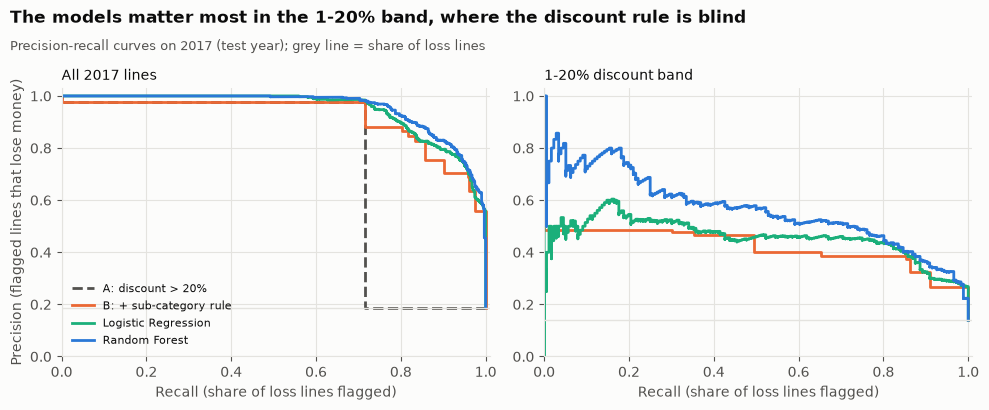

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (df, sc, heading) in zip(axes, [(test, scores_all, "All 2017 lines"),
                                        (mid, scores_mid, "1-20% discount band")]):
    for name, s in sc.items():
        if name.startswith("A") and heading.startswith("1-20"):
            continue   # Baseline A gives every band line the same score
        precision, recall, _ = precision_recall_curve(df[lm.TARGET], s)
        color, style = SCORER_STYLE[name]
        ax.plot(recall, precision, color=color, ls=style, lw=2, label=name, drawstyle="steps-post")
    ax.axhline(df[lm.TARGET].mean(), color=GRID, lw=1)
    ax.set_title(heading, loc="left", fontsize=10, color=TEXT)
    ax.set_xlabel("Recall (share of loss lines flagged)")
    ax.set_xlim(0, 1.01)
    ax.set_ylim(0, 1.03)
axes[0].set_ylabel("Precision (flagged lines that lose money)")
axes[0].legend(frameon=False, fontsize=8, loc="lower left")
add_titles(fig, "The models matter most in the 1-20% band, where the discount rule is blind",
           "Precision-recall curves on 2017 (test year); grey line = share of loss lines")
save(fig, "01_precision_recall")

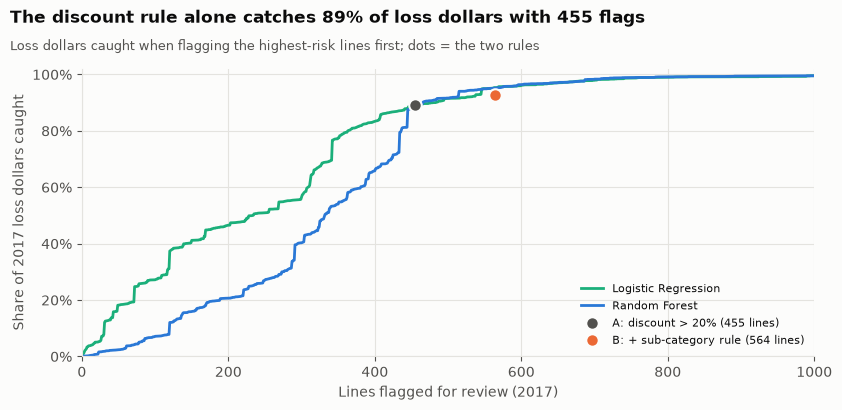

In [10]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
budgets = np.arange(1, len(test) + 1)
loss_dollars = -test.profit.clip(upper=0).to_numpy()
for name in ["Logistic Regression", "Random Forest"]:
    order = np.argsort(-scores_all[name], kind="stable")
    caught = np.cumsum(loss_dollars[order]) / loss_dollars.sum()
    color, style = SCORER_STYLE[name]
    ax.plot(budgets, caught * 100, color=color, ls=style, lw=2, label=name)
for name, n in [("A: discount > 20%", n_a), ("B: + sub-category rule", n_b)]:
    point = lm.operating_point(test, lm.baseline_a_scores(test) == 1 if name.startswith("A")
                               else baseline_b.flags(test))
    ax.plot(n, point["loss_dollars_caught"] * 100, "o", ms=9, color=SCORER_STYLE[name][0],
            markeredgecolor=SURFACE, markeredgewidth=1.5, label=f"{name} ({n} lines)")
ax.set_xlim(0, 1000)
ax.set_ylim(0, 102)
ax.yaxis.set_major_formatter("{x:.0f}%")
ax.set_xlabel("Lines flagged for review (2017)")
ax.set_ylabel("Share of 2017 loss dollars caught")
ax.legend(frameon=False, fontsize=8, loc="lower right")
add_titles(fig, "The discount rule alone catches 89% of loss dollars with 455 flags",
           "Loss dollars caught when flagging the highest-risk lines first; dots = the two rules")
save(fig, "02_loss_dollars_by_budget")

**Note on small review budgets:** the models rank lines by the *probability* of a loss,
not its size, so with fewer than ~455 flags they catch fewer loss dollars than the count
suggests (about 45% for the Random Forest and 70% for Logistic Regression after 300 flags).
If the model is used with a small budget, ranking by expected loss dollars would serve better.

## 4. Which features predict losses?

SHAP values from the Random Forest on 2017, with one-hot columns summed back into their
original feature, ranked by mean |SHAP|. Permutation importance (drop in PR-AUC when one
feature is shuffled) and the Logistic Regression coefficients are cross-checks.

In [11]:
_, shap_all = lm.grouped_shap(forest, test)
_, shap_mid = lm.grouped_shap(forest, mid)
perm = lm.grouped_permutation_importance(forest, test)
ranking = (shap_all.rename(columns={"mean_abs_shap": "SHAP, all lines"})
           .merge(shap_mid.rename(columns={"mean_abs_shap": "SHAP, 1-20% band"}), on="feature")
           .merge(perm[["feature", "pr_auc_drop"]].rename(columns={"pr_auc_drop": "permutation PR-AUC drop"}),
                  on="feature"))
show(ranking)
show(lm.logistic_coefficients(logistic).head(12))

feature,"SHAP, all lines","SHAP, 1-20% band",permutation PR-AUC drop
discount,0.205,0.112,0.481
state,0.081,0.068,0.021
sub_category,0.079,0.102,0.067
category,0.037,0.049,0.020
unit_price,0.028,0.038,0.019
region,0.020,0.020,0.001
order_month,0.009,0.013,0.001
ship_mode,0.007,0.010,0.001
segment,0.006,0.009,0.000
quantity,0.006,0.007,0.001


column,feature,coefficient
num__discount,discount,4.906
cat__sub_category_Storage,sub_category,3.193
cat__sub_category_Supplies,sub_category,2.805
cat__sub_category_Copiers,sub_category,-2.793
cat__sub_category_Accessories,sub_category,2.036
cat__sub_category_Paper,sub_category,-1.832
cat__sub_category_Binders,sub_category,-1.691
cat__sub_category_Art,sub_category,-1.533
cat__sub_category_Fasteners,sub_category,1.244
cat__category_Furniture,category,1.205


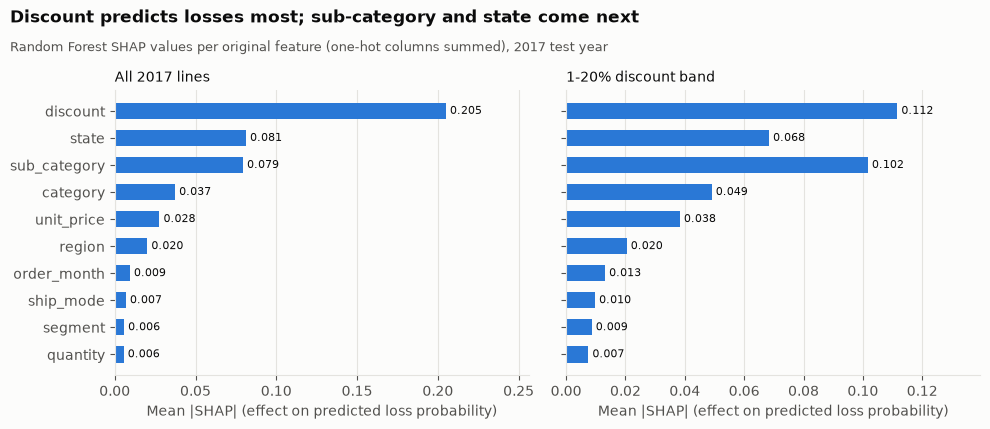

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), sharey=True)
order = ranking.sort_values("SHAP, all lines")["feature"]
for ax, column, heading in [(axes[0], "SHAP, all lines", "All 2017 lines"),
                            (axes[1], "SHAP, 1-20% band", "1-20% discount band")]:
    values = ranking.set_index("feature").loc[order, column]
    bars = ax.barh(order, values, color=BLUE, height=0.6)
    for bar, v in zip(bars, values):
        ax.annotate(f"{v:.3f}", (v, bar.get_y() + bar.get_height() / 2), xytext=(3, 0),
                    textcoords="offset points", va="center", fontsize=8, color=TEXT)
    ax.set_title(heading, loc="left", fontsize=10, color=TEXT)
    ax.set_xlabel("Mean |SHAP| (effect on predicted loss probability)")
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, ranking[column].max() * 1.25)
add_titles(fig, "Discount predicts losses most; sub-category and state come next",
           "Random Forest SHAP values per original feature (one-hot columns summed), 2017 test year")
save(fig, "03_shap_ranking")

**Reading the ranking carefully:** SHAP gives state about as much credit as sub-category,
but permutation importance gives state much less. Discounts are set by state, so the two
features carry overlapping information: shuffling state alone costs little because
discount still carries the signal, while SHAP splits the shared credit between them.
Discount comes first in every ranking and sub-category second or a close third. Ship
mode, customer segment, order month and quantity add almost nothing.

## Business insight

**Strongest predictors.** Discount is by far the strongest predictor of a loss-making line,
followed by sub-category and state, then category and list price. Ship mode, customer
segment, order month and quantity add almost nothing. Within the 1-20% band, sub-category
is nearly as important as discount.

**Better than a simple discount rule? Yes, but the gain is small in dollars.**
- The rule "flag if discount > 20%" already catches **89% of 2017 loss dollars** with 455
  flags, 98% of them correct. At that budget the models flag nearly the same lines and
  catch the same 89.3% of loss dollars.
- Adding sub-category in the 1-20% band (Baseline B) raises PR-AUC from 0.75 to 0.92;
  the Random Forest reaches 0.96. With 564 flags, the Random Forest catches 95% of loss
  dollars vs. 93% for Baseline B and 90% for the discount rule.
- In the 1-20% band, the Random Forest clearly beats Baseline B (PR-AUC 0.56 vs. 0.42,
  paired difference +0.14, 95% CI +0.09 to +0.20). But that band holds only about 11% of
  2017 loss dollars ($5,763 of $53,836).

**Recommendation** *(an inference, not a tested finding)*: use the discount rule as the
first line of control, since it is simple and catches most of the money. Add the model
only to review lines discounted 1-20%, where it finds loss-making lines the rule cannot.
This matches step 3: deep discounts are the main problem, and a model mainly helps at
the margin.

**Caveats:**
1. One test year (2017); loss rates were stable across years (18.4-18.9%), but a
   different discount policy in future years would change what the model learned.
2. Association, not cause: the model predicts risk; it does not show that removing a
   discount would remove the loss.
3. Discount and state are correlated, so their individual importances should not be
   over-read.
4. `unit_price` depends on the after-discount assumption from step 1.

In [13]:
con.close()